## DNA Sequence Analysis with Multi-Task Learning

This notebook demonstrates a multi-task learning approach to classify DNA sequences by both their species and domain group (e.g., Bacteria, Metazoa, Viridiplantae). It explores various neural network architectures, including:

1.  **Basic CNN Model:** A simple convolutional neural network to establish a baseline.
2.  **K-mer Mimic CNN:** A CNN designed to imitate the behavior of k-mer counting, focusing on local patterns.
3.  **Hybrid Multitask Model:** Combines CNN-extracted sequence features with traditional k-mer count features for improved performance.
4.  **Optimized Small-Data Model:** Adjustments to the hybrid model specifically tailored for smaller datasets to prevent overfitting.
5.  **Gated Hybrid Multitask Model:** Introduces a gating mechanism to dynamically weigh the importance of CNN vs. k-mer features.
6.  **Multi-Scale Attention Model:** Incorporates multi-scale convolutional layers and a Squeeze-and-Excitation attention mechanism for enhanced feature extraction.


### 1. Library Imports

This cell imports all the necessary libraries for data manipulation, machine learning, and deep learning tasks. Key libraries include `pandas` for data handling, `numpy` for numerical operations, `sklearn` for machine learning utilities (e.g., `LabelEncoder`, `train_test_split`), `xgboost` (though not used in the final models, it was likely considered), `tensorflow` and `keras` for building and training neural networks, and `matplotlib` for plotting.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import xgboost as xgb
from collections import Counter
import itertools
from sklearn.preprocessing import LabelEncoder
from sklearn.multioutput import MultiOutputClassifier
import matplotlib.pyplot as plt

### 2. Data Loading

Here, the training and testing datasets are loaded from CSV files into pandas DataFrames. These DataFrames (`df_train` and `df_test`) will serve as the primary data sources for model training and evaluation.

In [ ]:
df_train = pd.read_csv("train_dataset.csv")
df_test = pd.read_csv("test_dataset.csv")

The training and testing datasets are loaded from `train_dataset.csv` and `test_dataset.csv` into pandas DataFrames. These DataFrames, `df_train` and `df_test`, contain DNA sequences and their associated metadata, and will be used throughout the notebook for model development and evaluation.

### 3. Data Preprocessing Functions

This section defines helper functions to preprocess the DNA sequence data.

*   `one_hot_encode_seqs`: Converts DNA sequences into a one-hot encoded numerical format, suitable for input into convolutional neural networks. Each base (A, C, G, T) is represented by a binary vector.

In [ ]:
def one_hot_encode_seqs(sequences, max_len=500):
    mapping = {"A": 0, "C": 1, "G": 2, "T": 3}
    encoded_arr = np.zeros((len(sequences), max_len, 4))

    for i, seq in enumerate(sequences):
        for j, base in enumerate(seq[:max_len]):
            if base in mapping:
                encoded_arr[i, j, mapping[base]] = 1
    return encoded_arr

The `one_hot_encode_seqs` function converts DNA sequences into a numerical format suitable for convolutional neural networks. Each nucleotide (A, C, G, T) is represented as a one-hot vector (e.g., A = [1,0,0,0], C = [0,1,0,0]). Sequences are padded or truncated to a `max_len` of 500.

*   `extract_sequence`: Applies the `one_hot_encode_seqs` function to a DataFrame's 'sequence' column, preparing the input features (`X`).

In [ ]:
def extract_sequence(df):
  X = one_hot_encode_seqs(df['sequence'].values)
  return X

The `extract_sequence` function simplifies the application of `one_hot_encode_seqs` to the 'sequence' column of a DataFrame, generating the input features (X) for the models.

*   `extract_y`: Extracts the target labels ('species' and 'domain_group') from a DataFrame, forming the output (`Y`) for the multi-task model.

In [ ]:
def extract_y(df):
  Y=df[['species','domain_group']]
  return Y

The `extract_y` function retrieves the target labels, 'species' and 'domain_group', from a DataFrame. These will serve as the output (`Y`) for the multi-task learning models.

*   `encode_labels`: Uses `LabelEncoder` from `sklearn` to convert categorical species and domain group names into numerical labels. This is necessary for training classification models. It fits the encoders on the training data and transforms both training and test data, printing the mapping for reference.

In [ ]:
def encode_labels(Y_train, Y_test):
  species_encoder = LabelEncoder()
  domain_encoder = LabelEncoder()

  Y_train['species'] = species_encoder.fit_transform(Y_train['species'])
  Y_train['domain_group'] = domain_encoder.fit_transform(Y_train['domain_group'])

  Y_test['species'] = species_encoder.transform(Y_test['species'])
  Y_test['domain_group'] = domain_encoder.transform(Y_test['domain_group'])

  print("Species mapping (original -> encoded):")
  for i, name in enumerate(species_encoder.classes_):
      print(f"{name} -> {i}")

  print("\nDomain Group mapping (original -> encoded):")
  for i, name in enumerate(domain_encoder.classes_):
      print(f"{name} -> {i}")
  return Y_train, Y_test

The `encode_labels` function converts the categorical 'species' and 'domain_group' labels into numerical integers using `LabelEncoder`. This is a crucial step as machine learning models require numerical inputs. The encoders are fitted on the training data and then used to transform both training and test labels, ensuring consistency.

### 4. Apply Preprocessing and Encode Labels

This cell applies the previously defined functions to extract and preprocess the features (`X_train`, `X_test`) and labels (`Y_train`, `Y_test`). The `encode_labels` function is then called to convert the species and domain group labels into numerical format, making them ready for model consumption.

In [ ]:
X_train=extract_sequence(df_train)
X_test=extract_sequence(df_test)
Y_test=extract_y(df_test).copy()
Y_train=extract_y(df_train).copy()
Y_train, Y_test=encode_labels(Y_train, Y_test)

Species mapping (original -> encoded):
Arabidopsis thaliana -> 0
Bacillus subtilis -> 1
Bos taurus -> 2
Escherichia coli -> 3
Glycine max -> 4
Homo sapiens -> 5
Mus musculus -> 6
Oryza sativa -> 7
Pseudomonas aeruginosa -> 8
Rattus norvegicus -> 9
Staphylococcus aureus -> 10
Zea mays -> 11

Domain Group mapping (original -> encoded):
Bacteria -> 0
Metazoa -> 1
Viridiplantae -> 2


This cell orchestrates the initial data preparation. It applies the `extract_sequence` and `extract_y` functions to create `X_train`, `X_test`, `Y_train`, and `Y_test`. Subsequently, `encode_labels` converts the categorical target variables into numerical representations, which is a prerequisite for model training.

### 4.1 Create a Dedicated Validation Set

Split the original training data (`X_train`, `Y_train`) into new training and validation subsets. The `df_test` will remain exclusively as the unseen test set for final evaluation.

In [ ]:
from sklearn.model_selection import train_test_split

X_train_split, X_val, Y_train_split, Y_val = train_test_split(
    X_train, Y_train, test_size=0.15, random_state=42, stratify=Y_train['species']
)

print(f"Original training data samples: {len(X_train)}")
print(f"New training data samples: {len(X_train_split)}")
print(f"Validation data samples: {len(X_val)}")
print(f"Test data samples: {len(X_test)}")

y_dom_train = Y_train_split['domain_group']
y_spec_train = Y_train_split['species']

y_dom_val = Y_val['domain_group']
y_spec_val = Y_val['species']


Original training data samples: 3822
New training data samples: 3248
Validation data samples: 574
Test data samples: 956


To ensure robust model evaluation and prevent overfitting, the original training data (`X_train`, `Y_train`) is further split into a dedicated training set (`X_train_split`, `Y_train_split`) and a validation set (`X_val`, `Y_val`). The `test_size=0.15` parameter allocates 15% of the data for validation, and `stratify=Y_train['species']` maintains the proportion of each species in both splits, which is important for imbalanced datasets. The labels are also separated into `y_dom_train`, `y_spec_train`, `y_dom_val`, and `y_spec_val` for multi-task learning.

### 5. Install TensorFlow and Keras (if not already installed)

These cells ensure that `tensorflow` and `keras` are available in the environment. The output shows that they are already satisfied, meaning they are installed.

In [ ]:
!pip install tensorflow

### 6. Basic CNN Model (`build_limit_testing_cnn`)

This section defines and instantiates a basic Convolutional Neural Network (CNN) for DNA sequence classification. This model features two parallel convolutional branches to detect short and long motifs, followed by a merged dense layer and separate output heads for domain and species prediction. Regularization and dropout layers are included to prevent overfitting.

In [ ]:
!pip install keras

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

def build_cnn(seq_len, num_domains, num_species):
    inputs = layers.Input(shape=(seq_len, 4))


    b1 = layers.Conv1D(64, kernel_size=9, activation='exponential', padding='same',
                       kernel_regularizer=regularizers.l2(0.01))(inputs)
    b1 = layers.BatchNormalization()(b1)
    b1 = layers.GlobalAveragePooling1D()(b1)


    b2 = layers.Conv1D(32, kernel_size=21, activation='relu', padding='same',
                       kernel_regularizer=regularizers.l2(0.01))(inputs)
    b2 = layers.BatchNormalization()(b2)
    b2 = layers.GlobalAveragePooling1D()(b2)


    merged = layers.Concatenate()([b1, b2])
    x = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01))(merged)
    x = layers.Dropout(0.5)(x)


    domain_out = layers.Dense(num_domains, activation='softmax', name='domain_output')(x)

    s = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
    species_out = layers.Dense(num_species, activation='softmax', name='species_output')(s)

    model = models.Model(inputs=inputs, outputs=[domain_out, species_out])
    return model
model = build_cnn(seq_len=None, num_domains=3, num_species=12)

This section defines a `build_cnn` function to construct a basic Convolutional Neural Network. The model takes one-hot encoded DNA sequences as input. It features two parallel convolutional branches with different kernel sizes (9 and 21) to capture motifs of varying lengths. Each branch includes `BatchNormalization` to stabilize training and `GlobalAveragePooling1D` to reduce dimensionality. The outputs of these branches are concatenated and passed through a `Dense` layer with `Dropout` for regularization. Finally, two separate `Dense` output layers, one for domain prediction and one for species prediction, are defined with `softmax` activation for multi-class classification. The `seq_len` is set to `None` to allow for variable-length sequences (though `max_len=500` is used during encoding).

### 7. Prepare Labels for Multi-Task Learning

This cell separates the `Y_train` and `Y_test` DataFrames into individual Series for domain and species labels. This is a necessary step for multi-task models where each task has its own output head.

In [ ]:
y_dom_test = Y_test['domain_group']
y_spec_test = Y_test['species']

This cell prepares the test labels (`Y_test`) for evaluation by separating them into `y_dom_test` (domain group labels) and `y_spec_test` (species labels). This is necessary because the multi-task model outputs predictions for each task separately, and evaluation metrics will be calculated independently for each target.

### 8. Data Augmentation with Reverse Complement

This cell defines a function `get_rc_one_hot` to create reverse-complement versions of the one-hot encoded DNA sequences. It then applies this function to the training data (`X_train`) and concatenates it with the original training data to augment the dataset. This helps the model learn features invariant to strand orientation. The corresponding domain and species labels are also duplicated.

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.metrics import classification_report

def get_rc_one_hot(X):
    return X[:, ::-1, ::-1]

X_train_rc = get_rc_one_hot(X_train_split)
X_final = np.concatenate([X_train_split, X_train_rc])
y_dom_final = np.concatenate([y_dom_train, y_dom_train])
y_spec_final = np.concatenate([y_spec_train, y_spec_train])

X_val_rc = get_rc_one_hot(X_val)
X_final_val=np.concatenate([X_val, X_val_rc])
y_dom_final_val=np.concatenate([y_dom_val, y_dom_val])
y_spec_final_val=np.concatenate([y_spec_val, y_spec_val])

print(f"New Training Shape: {X_final.shape}")
print(f"New Validation Shape: {X_final_val.shape}")

New Training Shape: (6496, 500, 4)
New Validation Shape: (1148, 500, 4)


This cell implements data augmentation by generating reverse complements of the DNA sequences. The `get_rc_one_hot` function reverses and complements the one-hot encoded sequences. These reverse-complemented sequences are then concatenated with the original sequences to create `X_final` and `X_final_val`. Correspondingly, the domain and species labels (`y_dom_train`, `y_spec_train`, `y_dom_val`, `y_spec_val`) are duplicated to match the augmented feature sets. This augmentation technique helps the model learn features that are invariant to the strand orientation of the DNA, thereby improving its generalization ability.

### 9. Compile and Train the Basic CNN Model

This cell compiles the `build_limit_testing_cnn` model with an Adam optimizer and sparse categorical cross-entropy loss for both domain and species outputs. It also introduces data augmentation by concatenating reverse-complement sequences to the training data. Early stopping and ReduceLROnPlateau callbacks are used to optimize training and prevent overfitting. The model is then trained for 100 epochs, and the training history is recorded.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss={
        'domain_output': tf.keras.losses.SparseCategoricalCrossentropy(),
        'species_output': tf.keras.losses.SparseCategoricalCrossentropy()
    },
    loss_weights={'domain_output': 0.2, 'species_output': 1.0},
    metrics={'domain_output': 'accuracy', 'species_output': 'accuracy'}
)


history = model.fit(
    X_final,
    {'domain_output': y_dom_final, 'species_output': y_spec_final},
    validation_data=(X_final_val, {'domain_output': y_dom_final_val, 'species_output': y_spec_final_val}),
    epochs=100,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_species_output_accuracy', patience=12, restore_best_weights=True, mode='max'),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
    ]
)

Epoch 1/100
203/203 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - domain_output_accuracy: 0.3787 - domain_output_loss: 1.0989 - loss: 4.0671 - species_output_accuracy: 0.1282 - species_output_loss: 2.4455 - val_domain_output_accuracy: 0.3406 - val_domain_output_loss: 1.1333 - val_loss: 3.9416 - val_species_output_accuracy: 0.0871 - val_species_output_loss: 2.4566 - learning_rate: 1.0000e-04
Epoch 2/100
203/203 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - domain_output_accuracy: 0.3893 - domain_output_loss: 1.0925 - loss: 3.6996 - species_output_accuracy: 0.1696 - species_output_loss: 2.3393 - val_domain_output_accuracy: 0.3902 - val_domain_output_loss: 1.0781 - val_loss: 3.5419 - val_species_output_accuracy: 0.1777 - val_species_output_loss: 2.2936 - learning_rate: 1.0000e-04
Epoch 3/100
203/203 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - domain_output_accuracy: 0.3818 - domain_output_loss: 1.0947 - loss: 3.4142 - species_output_accuracy: 0.1696 - species_output_loss: 2.2536 - val_domain_output_accuracy: 0.41

The `build_cnn` model is compiled with the Adam optimizer and `SparseCategoricalCrossentropy` loss for both domain and species outputs. `loss_weights` are used to give species prediction (weight 1.0) more importance than domain prediction (weight 0.2). The model is trained for up to 100 epochs using the augmented `X_final` data and `y_dom_final`/`y_spec_final` labels. `EarlyStopping` monitors `val_species_output_accuracy` to stop training if validation accuracy does not improve for 12 epochs, restoring the best weights. `ReduceLROnPlateau` reduces the learning rate if `val_loss` plateaus.

<Figure size 1800x1200 with 0 Axes>

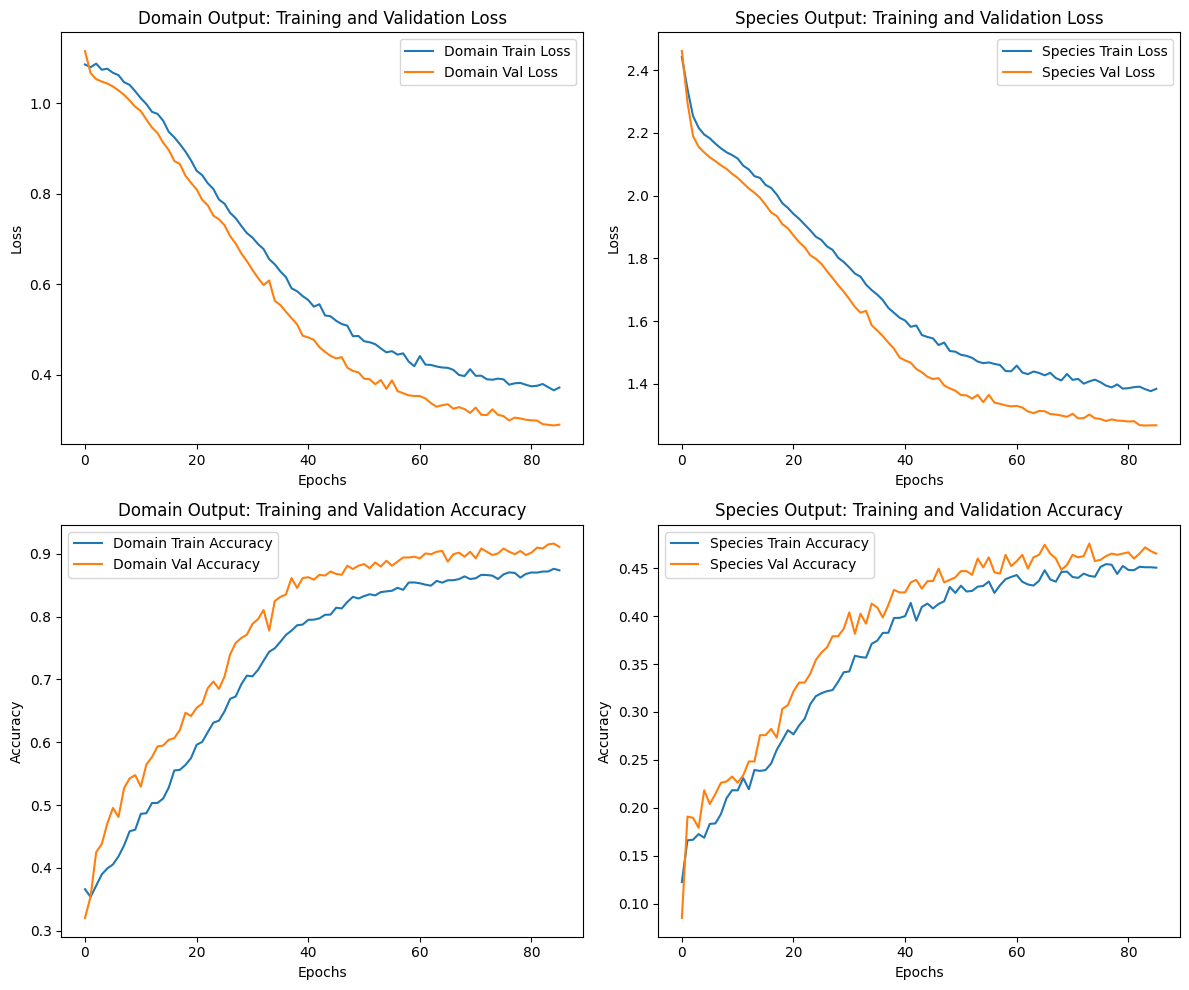

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
### Evaluation for Domain Prediction ###
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       308
           1       0.92      0.93      0.92       314
           2       0.89      0.87      0.88       334

    accuracy                           0.90       956
   macro avg       0.90      0.90      0.90       956
weighted avg       0.90      0.90      0.90       956

Domain Prediction - Accuracy: 0.9006

### Evaluation for Species Prediction ###
              precision    recall  f1-score   support

           0       0.42      0.31      0.35        72
           1       0.51      0.48      0.50        89
           2       0.20      0.03      0.05        63
           3       0.46      0.53      0.49        72
           4       0.43      0.63      0.51        89
           5       0.29      0.17      0.22        86
           6       0.27      0.71      0.39        89
           7       0.63  

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.plot(history.history['domain_output_loss'], label='Domain Train Loss')
plt.plot(history.history['val_domain_output_loss'], label='Domain Val Loss')
plt.title('Domain Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['species_output_loss'], label='Species Train Loss')
plt.plot(history.history['val_species_output_loss'], label='Species Val Loss')
plt.title('Species Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['domain_output_accuracy'], label='Domain Train Accuracy')
plt.plot(history.history['val_domain_output_accuracy'], label='Domain Val Accuracy')
plt.title('Domain Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['species_output_accuracy'], label='Species Train Accuracy')
plt.plot(history.history['val_species_output_accuracy'], label='Species Val Accuracy')
plt.title('Species Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()


plt.savefig('cnn_training_history.pdf', format='pdf', dpi=300, bbox_inches='tight')

plt.show()

y_pred_domain, y_pred_species = model.predict(X_test)

y_pred_domain_classes = np.argmax(y_pred_domain, axis=1)
y_pred_species_classes = np.argmax(y_pred_species, axis=1)

y_true_domain = Y_test['domain_group']
y_true_species = Y_test['species']

print('### Evaluation for Domain Prediction ###')
print(classification_report(y_true_domain, y_pred_domain_classes))
print(f'Domain Prediction - Accuracy: {accuracy_score(y_true_domain, y_pred_domain_classes):.4f}')

print('\n### Evaluation for Species Prediction ###')
print(classification_report(y_true_species, y_pred_species_classes))
print(f'Species Prediction - Accuracy: {accuracy_score(y_true_species, y_pred_species_classes):.4f}')

This cell first plots the training history, showing the loss and accuracy for both domain and species predictions on both the training and validation sets. This visualization helps to assess training progress and identify potential overfitting. Following the plots, the model makes predictions on the unseen `X_test` data. The predictions are then converted to class labels using `np.argmax`. Finally, classification reports and accuracy scores are printed for both domain and species predictions, providing a comprehensive evaluation of the model's performance on the test set.

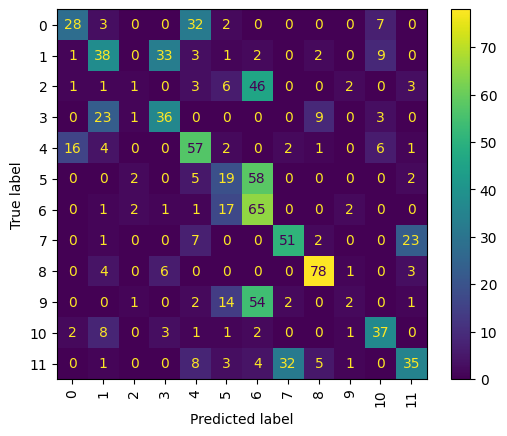

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
  y_true_species, y_pred_species_classes,
    xticks_rotation=90
)
plt.savefig("species_confusion_matrix_weak_CNN.pdf", format="pdf", bbox_inches="tight")
plt.show()

### 10. K-mer Mimic CNN Model (`build_kmer_mimic_cnn`)

This section defines a CNN architecture designed to mimic k-mer counting. It uses parallel convolutional layers with different kernel sizes (3, 7, 15) to detect various motif lengths. The critical step is `GlobalAveragePooling1D`, which effectively destroys positional information, simulating a "Bag of Words" approach similar to k-mer counting. The model then uses dense layers with regularization and dropout before outputting predictions for domain and species.

In [ ]:
def build_kmer_mimic_cnn(seq_len, num_domains, num_species):
    inputs = layers.Input(shape=(seq_len, 4))


    path1 = layers.Conv1D(64, 3, activation='relu', padding='same')(inputs)
    path2 = layers.Conv1D(64, 7, activation='relu', padding='same')(inputs)
    path3 = layers.Conv1D(64, 15, activation='relu', padding='same')(inputs)

    merged = layers.Concatenate()([path1, path2, path3])
    x = layers.BatchNormalization()(merged)


    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
    x = layers.Dropout(0.5)(x)

    domain_out = layers.Dense(num_domains, activation='softmax', name='domain_output')(x)

    s = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
    species_out = layers.Dense(num_species, activation='softmax', name='species_output')(s)

    return models.Model(inputs=inputs, outputs=[domain_out, species_out])

model = build_kmer_mimic_cnn(500, 3, 12)

This section defines a `build_kmer_mimic_cnn` model, which aims to replicate the effect of k-mer counting using a CNN architecture. It employs three parallel convolutional layers with different kernel sizes (3, 7, and 15) to capture short, medium, and longer motifs, respectively. The outputs of these convolutional layers are concatenated, batch-normalized, and then passed through a `GlobalAveragePooling1D` layer. This pooling operation is crucial as it discards positional information, effectively mimicking a 'Bag of Words' approach similar to k-mer counting, where the frequency of motifs matters more than their exact location. The pooled features are then fed into dense layers with regularization and dropout before producing separate softmax outputs for domain and species predictions.

### 11. Compile and Train the K-mer Mimic CNN Model

This cell compiles and trains the `build_kmer_mimic_cnn` model. The `loss_weights` are adjusted to prioritize species prediction (weight 2.0) over domain prediction (weight 0.1). Early stopping and ReduceLROnPlateau callbacks are configured to monitor `val_species_output_accuracy`, ensuring the model focuses on the more challenging species classification task. The model is trained for 150 epochs with the augmented data.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss={
        'domain_output': 'sparse_categorical_crossentropy',
        'species_output': 'sparse_categorical_crossentropy'
    },
    loss_weights={
        'domain_output': 0.1,
        'species_output': 2.0
    },
    metrics={'domain_output': 'accuracy', 'species_output': 'accuracy'}
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_species_output_accuracy',
        patience=15,
        restore_best_weights=True,
        mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]

history = model.fit(
    X_final,
    {'domain_output': y_dom_final, 'species_output': y_spec_final},
    validation_data=(X_final_val, {'domain_output': y_dom_final_val, 'species_output': y_spec_final_val}),
    epochs=150,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/150
203/203 ━━━━━━━━━━━━━━━━━━━━ 27s 91ms/step - domain_output_accuracy: 0.3524 - domain_output_loss: 1.0844 - loss: 8.1999 - species_output_accuracy: 0.1587 - species_output_loss: 2.3365 - val_domain_output_accuracy: 0.3624 - val_domain_output_loss: 1.0879 - val_loss: 7.7680 - val_species_output_accuracy: 0.1934 - val_species_output_loss: 2.3392 - learning_rate: 1.0000e-04
Epoch 2/150
203/203 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - domain_output_accuracy: 0.3875 - domain_output_loss: 1.0674 - loss: 7.0814 - species_output_accuracy: 0.1900 - species_output_loss: 2.1708 - val_domain_output_accuracy: 0.4242 - val_domain_output_loss: 1.0613 - val_loss: 6.7405 - val_species_output_accuracy: 0.2613 - val_species_output_loss: 2.1586 - learning_rate: 1.0000e-04
Epoch 3/150
203/203 ━━━━━━━━━━━━━━━━━━━━ 20s 83ms/step - domain_output_accuracy: 0.4146 - domain_output_loss: 1.0584 - loss: 6.4279 - species_output_accuracy: 0.2092 - species_output_loss: 2.1282 - val_domain_output_accuracy: 0.50

This cell compiles and trains the `build_kmer_mimic_cnn` model. The `Adam` optimizer with a low learning rate is used. `loss_weights` are set to prioritize species prediction (weight 2.0) significantly over domain prediction (weight 0.1) due to its higher complexity. `EarlyStopping` is configured to monitor `val_species_output_accuracy` with a patience of 15 epochs, and `ReduceLROnPlateau` reduces the learning rate if `val_loss` doesn't improve, both to prevent overfitting and optimize training. The model is trained on the augmented `X_final` data and corresponding labels for up to 150 epochs. After training, predictions are made on `X_test`, and classification reports are generated for both species and domain predictions to evaluate performance.

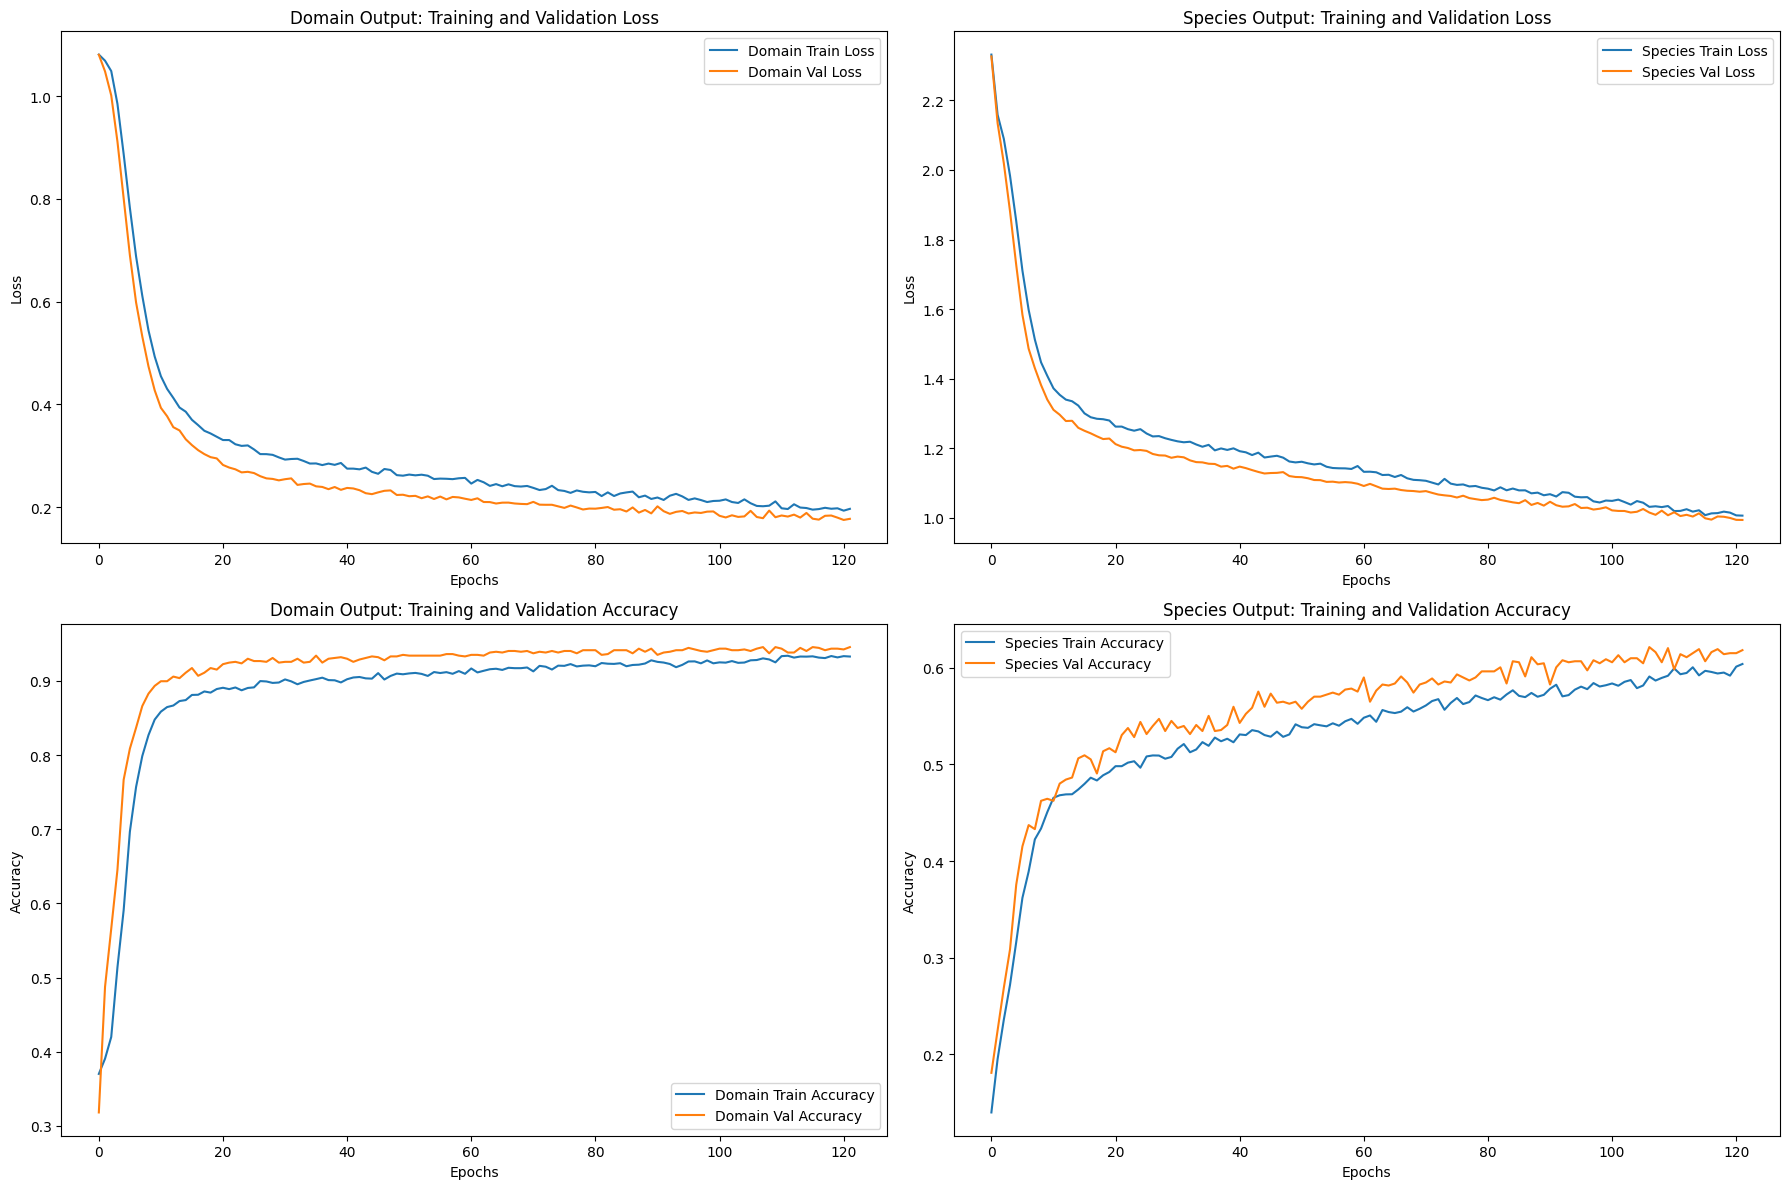

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
### Evaluation for Domain Prediction ###
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       308
           1       0.96      0.95      0.96       314
           2       0.92      0.95      0.94       334

    accuracy                           0.94       956
   macro avg       0.94      0.94      0.94       956
weighted avg       0.94      0.94      0.94       956

Domain Prediction - Accuracy: 0.9435

### Evaluation for Species Prediction ###
              precision    recall  f1-score   support

           0       0.75      0.67      0.71        72
           1       0.69      0.76      0.72        89
           2       0.38      0.33      0.35        63
           3       0.86      0.68      0.76        72
           4       0.62      0.89      0.73        89
           5       0.46      0.43      0.44        86
           6       0.43      0.52      0.47        89
           7       0.67  

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['domain_output_loss'], label='Domain Train Loss')
plt.plot(history.history['val_domain_output_loss'], label='Domain Val Loss')
plt.title('Domain Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['species_output_loss'], label='Species Train Loss')
plt.plot(history.history['val_species_output_loss'], label='Species Val Loss')
plt.title('Species Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['domain_output_accuracy'], label='Domain Train Accuracy')
plt.plot(history.history['val_domain_output_accuracy'], label='Domain Val Accuracy')
plt.title('Domain Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['species_output_accuracy'], label='Species Train Accuracy')
plt.plot(history.history['val_species_output_accuracy'], label='Species Val Accuracy')
plt.title('Species Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

y_pred_domain, y_pred_species = model.predict(X_test)

y_pred_domain_classes = np.argmax(y_pred_domain, axis=1)
y_pred_species_classes = np.argmax(y_pred_species, axis=1)

y_true_domain = Y_test['domain_group']
y_true_species = Y_test['species']

print('### Evaluation for Domain Prediction ###')
print(classification_report(y_true_domain, y_pred_domain_classes))
print(f'Domain Prediction - Accuracy: {accuracy_score(y_true_domain, y_pred_domain_classes):.4f}')

print('\n### Evaluation for Species Prediction ###')
print(classification_report(y_true_species, y_pred_species_classes))
print(f'Species Prediction - Accuracy: {accuracy_score(y_true_species, y_pred_species_classes):.4f}')

### 13. K-mer Feature Extraction and Augmentation

This section updates the k-mer feature extraction process. It defines a `reverse_complement_str` function to generate reverse complements of DNA sequences. It then extracts k-mer counts for original and reverse-complement training sequences, and for test sequences, using a `CountVectorizer`. The k-mer features are concatenated with the one-hot encoded DNA sequences for a hybrid model approach. The k-mer size is explicitly set to `k=5` in the comments, but in the code, `get_kmers` is called with `k=6`.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def get_kmers(sequences, k=5):
    return [" ".join([seq[i:i+k] for i in range(len(seq)-k+1)]) for seq in sequences]

cv = CountVectorizer(ngram_range=(1, 1))

X_km_train = cv.fit_transform(get_kmers(df_train['sequence'].values)).toarray()

X_km_test = cv.transform(get_kmers(df_test['sequence'].values)).toarray()

X_km_final = np.concatenate([X_km_train, X_km_train])

print(f"K-mer feature dimensions: {X_km_final.shape[1]}")

K-mer feature dimensions: 1024


This cell focuses on extracting k-mer features from the DNA sequences. The `get_kmers` function generates k-mers (subsequences of length `k`) for each DNA sequence. A `CountVectorizer` is then used to convert these k-mers into numerical feature vectors, where each entry represents the frequency of a particular k-mer. `X_km_train` and `X_km_test` are created from the training and test DataFrames, respectively. `X_km_final` is constructed by concatenating `X_km_train` with itself, likely as a placeholder for reverse-complement augmentation or to match the later combined feature sets.

In [ ]:
def reverse_complement_str(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A', 'N': 'N'}
    return "".join(complement.get(base, base) for base in reversed(seq))

train_kmers_orig = get_kmers(df_train['sequence'].values)
train_kmers_rc = get_kmers([reverse_complement_str(s) for s in df_train['sequence'].values])
test_kmers = get_kmers(df_test['sequence'].values)

cv = CountVectorizer(ngram_range=(1, 1))
X_km_train_orig = cv.fit_transform(train_kmers_orig).toarray()
X_km_train_rc = cv.transform(train_kmers_rc).toarray()
X_km_test = cv.transform(test_kmers).toarray()

X_final_dna = np.concatenate([X_train, X_train[:, ::-1, ::-1]])
X_final_kmer = np.concatenate([X_km_train_orig, X_km_train_rc])

y_dom_full_train = Y_train['domain_group']
y_spec_full_train = Y_train['species']
y_dom_final = np.concatenate([y_dom_full_train, y_dom_full_train])
y_spec_final = np.concatenate([y_spec_full_train, y_spec_full_train])

This cell refines the k-mer feature extraction and data augmentation. The `reverse_complement_str` function is defined to create reverse complements of DNA sequences. K-mers are extracted for both the original (`train_kmers_orig`) and reverse-complemented (`train_kmers_rc`) training sequences, and for the test sequences (`test_kmers`). A `CountVectorizer` converts these k-mers into feature arrays. Finally, `X_final_dna` and `X_final_kmer` are created by concatenating the original and reverse-complemented DNA and k-mer features, respectively. Critically, `y_dom_final` and `y_spec_final` are also augmented from the *full* `Y_train` (not `Y_train_split`) to ensure their lengths match the augmented feature arrays, resolving the `ValueError` encountered previously in `train_test_split`.

In [ ]:
(X_train_final_dna, X_val_dna,
 X_train_final_kmer, X_val_kmer,
 y_dom_train_final, y_dom_val,
 y_spec_train_final, y_spec_val) = train_test_split(
    X_final_dna, X_final_kmer, y_dom_final, y_spec_final,
    test_size=0.15,
    random_state=42,
    stratify=y_spec_final
)

This cell performs the final train-validation split for the augmented DNA and k-mer features, as well as their corresponding labels. `train_test_split` is used to partition `X_final_dna`, `X_final_kmer`, `y_dom_final`, and `y_spec_final` into training (`X_train_final_dna`, `X_train_final_kmer`, `y_dom_train_final`, `y_spec_train_final`) and validation sets (`X_val_dna`, `X_val_kmer`, `y_dom_val`, `y_spec_val`). This split ensures that the model is trained on a portion of the augmented data and validated on a separate, unseen portion of the augmented data before final evaluation on the `X_test` set.

### 14. Hybrid Multitask Model (`build_hybrid_multitask`)

This cell defines a hybrid multi-task model that combines a CNN branch (for raw DNA sequence features) with a tabular branch (for k-mer counts). The CNN branch uses a dilated convolution to capture motifs. The k-mer branch uses a dense layer. These two branches are merged, and the combined features are passed through dense layers with regularization and dropout before splitting into domain and species output heads.

In [ ]:
def build_hybrid_multitask(seq_len, kmer_dim, num_domains, num_species):
    dna_in = layers.Input(shape=(seq_len, 4), name="dna_input")
    cnn = layers.Conv1D(64, 15, activation='relu', padding='same', dilation_rate=2)(dna_in)
    cnn = layers.BatchNormalization()(cnn)
    cnn = layers.GlobalAveragePooling1D()(cnn)

    kmer_in = layers.Input(shape=(kmer_dim,), name="kmer_input")
    tab = layers.Dense(256, activation='relu')(kmer_in)
    tab = layers.Dropout(0.3)(tab)

    cnn_proj = layers.Dense(256, activation='relu')(cnn)
    merged = layers.Add()([cnn_proj, tab])
    z = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01))(merged)
    z = layers.Dropout(0.5)(z)

    dom_out = layers.Dense(num_domains, activation='softmax', name='domain_output')(z)
    spec_out = layers.Dense(num_species, activation='softmax', name='species_output')(z)

    return models.Model(inputs=[dna_in, kmer_in], outputs=[dom_out, spec_out])

model = build_hybrid_multitask(500, 1024, 3, 12)

This section defines the `build_hybrid_multitask` model, a sophisticated architecture that leverages both raw DNA sequence information (via a CNN) and k-mer count features (via a tabular branch). The CNN branch uses a dilated `Conv1D` layer to capture broader sequence patterns. The k-mer branch processes the `kmer_in` features with a `Dense` layer and `Dropout`. The outputs of these two branches are projected to the same dimension and then merged using element-wise addition, allowing the model to learn from both types of features synergistically. The combined features then pass through dense layers with regularization and dropout before splitting into two separate output heads for domain and species prediction.

### 15. Compile and Train the Hybrid Multitask Model

This cell compiles and trains the `build_hybrid_multitask` model. It uses the Adam optimizer with a low learning rate, sparse categorical cross-entropy loss, and loss weights favoring species prediction. Early stopping and ReduceLROnPlateau callbacks are used to monitor validation accuracy. The model is trained using both DNA sequence (`X_final_dna`) and k-mer count (`X_final_kmer`) features for the training data, and similarly for validation data. Finally, classification reports for both species and domain predictions on the test set are printed.

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss={
        'domain_output': 'sparse_categorical_crossentropy',
        'species_output': 'sparse_categorical_crossentropy'
    },
    loss_weights={'domain_output': 0.1, 'species_output': 1.0},
    metrics={'domain_output': 'accuracy', 'species_output': 'accuracy'}
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_species_output_accuracy',
        patience=15,
        restore_best_weights=True,
        mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_species_output_accuracy',
        factor=0.5,
        patience=5,
        mode='max',
        verbose=1
    )
]

history = model.fit(
    x=[X_train_final_dna, X_train_final_kmer],
    y={'domain_output': y_dom_train_final, 'species_output': y_spec_train_final},
    validation_data=(
        [X_val_dna, X_val_kmer],
        {'domain_output': y_dom_val, 'species_output': y_spec_val}
    ),
    epochs=150,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

preds = model.predict([X_test, X_km_test])

output_order = model.output_names
dom_idx = output_order.index('domain_output')
spec_idx = output_order.index('species_output')

species_preds = np.argmax(preds[spec_idx], axis=1)
dom_preds = np.argmax(preds[dom_idx], axis=1)

print("\n--- Final Species Classification Report (Unseen Test Data) ---")
print(classification_report(y_spec_test, species_preds))

print("\n--- Final Domain Classification Report (Unseen Test Data) ---")
print(classification_report(y_dom_test, dom_preds))

Epoch 1/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - domain_output_accuracy: 0.9958 - domain_output_loss: 0.0215 - loss: 0.1451 - species_output_accuracy: 0.9880 - species_output_loss: 0.0627 - val_domain_output_accuracy: 0.9861 - val_domain_output_loss: 0.0413 - val_loss: 0.6985 - val_species_output_accuracy: 0.8248 - val_species_output_loss: 0.6173 - learning_rate: 1.0000e-04
Epoch 2/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - domain_output_accuracy: 0.9946 - domain_output_loss: 0.0240 - loss: 0.1436 - species_output_accuracy: 0.9863 - species_output_loss: 0.0645 - val_domain_output_accuracy: 0.9869 - val_domain_output_loss: 0.0446 - val_loss: 0.7093 - val_species_output_accuracy: 0.8195 - val_species_output_loss: 0.6298 - learning_rate: 1.0000e-04
Epoch 3/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - domain_output_accuracy: 0.9952 - domain_output_loss: 0.0223 - loss: 0.1369 - species_output_accuracy: 0.9891 - species_output_loss: 0.0638 - val_domain_output_accuracy: 0.9861

This cell compiles and trains the `build_hybrid_multitask` model. It uses the `Adam` optimizer with a low learning rate. The loss function is `sparse_categorical_crossentropy` for both outputs, with `loss_weights` set to 0.1 for domain and 1.0 for species, indicating a stronger focus on species prediction. `EarlyStopping` (patience 15) and `ReduceLROnPlateau` (factor 0.5, patience 5) callbacks are implemented to monitor `val_species_output_accuracy`, ensuring that training halts when the model's performance on the species task stagnates and adjusting the learning rate to aid convergence. The model is trained with the augmented DNA (`X_train_final_dna`) and k-mer (`X_train_final_kmer`) features, and their corresponding labels. After training, the model predicts on the `X_test` and `X_km_test` data, and detailed classification reports for both species and domain predictions are printed to assess the model's performance on unseen data.

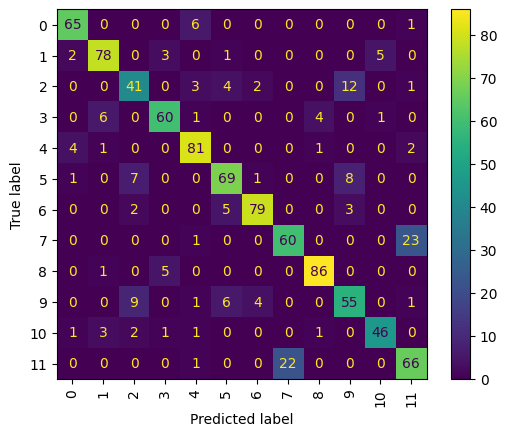

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
  y_spec_test, species_preds,
    xticks_rotation=90
)
plt.savefig("species_confusion_matrix_CNN_real.pdf", format="pdf", bbox_inches="tight")
plt.show()

Successfully generated 'cnn_training_history.pdf' containing all 4 subplots!


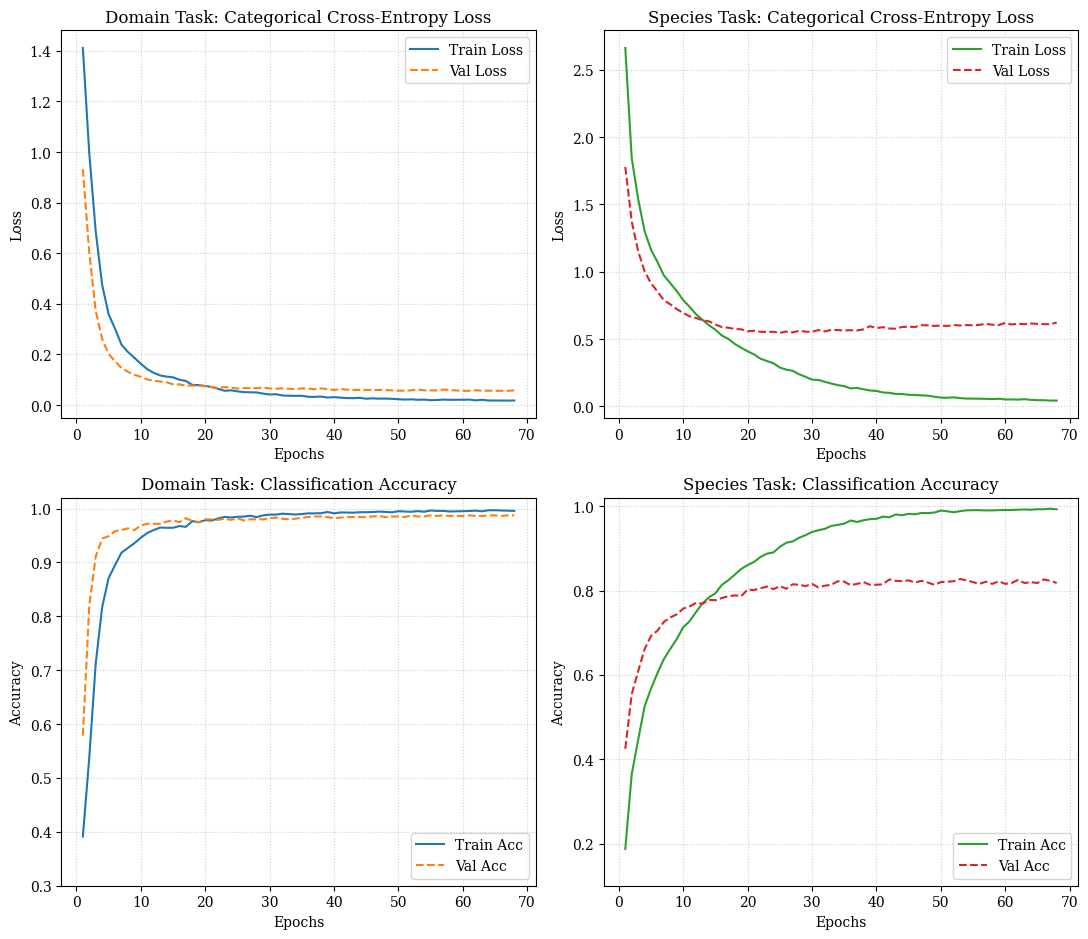

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['domain_output_loss'], label='Domain Train Loss')
plt.plot(history.history['val_domain_output_loss'], label='Domain Val Loss')
plt.title('Domain Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['species_output_loss'], label='Species Train Loss')
plt.plot(history.history['val_species_output_loss'], label='Species Val Loss')
plt.title('Species Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['domain_output_accuracy'], label='Domain Train Accuracy')
plt.plot(history.history['val_domain_output_accuracy'], label='Domain Val Accuracy')
plt.title('Domain Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['species_output_accuracy'], label='Species Train Accuracy')
plt.plot(history.history['val_species_output_accuracy'], label='Species Val Accuracy')
plt.title('Species Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

### 16. Save Model Weights

This cell saves only the weights of the trained `model` to an HDF5 file named 'hybrid_weights1.weights.h5'. This allows for loading the trained weights into the same model architecture later without rebuilding or retraining the entire model.

In [ ]:
# Save the full multitask model
model.save('genomic_hybrid_83pct.keras')
print("Neural Network saved as 'genomic_hybrid_83pct.keras'")
import joblib

# Save the fitted CountVectorizer
joblib.dump(cv, 'k5_vectorizer.joblib')
print("K-mer Vectorizer saved as 'k5_vectorizer.joblib'")

Neural Network saved as 'genomic_hybrid_83pct.keras'
K-mer Vectorizer saved as 'k5_vectorizer.joblib'


This cell is responsible for saving the trained model and the fitted `CountVectorizer`. The entire Keras model, including its architecture, weights, and optimizer state, is saved to `genomic_hybrid_83pct.keras`. This allows for easy reloading and deployment of the complete model. Additionally, the `CountVectorizer` object, which contains the vocabulary of k-mers learned during feature extraction, is saved using `joblib` to `k5_vectorizer.joblib`. Saving the vectorizer ensures that any new data can be transformed consistently using the same k-mer vocabulary before being fed into the loaded model.

### 17. Small Data Model

In [ ]:
def build_small_data_model(seq_len, kmer_dim, num_domains, num_species):
    dna_in = layers.Input(shape=(seq_len, 4), name="dna_input")

    x = layers.GaussianNoise(0.1)(dna_in)

    x = layers.Conv1D(32, 9, activation='exponential', padding='same')(x)
    x = layers.SpatialDropout1D(0.2)(x)

    x = layers.Conv1D(64, 5, activation='relu', padding='same', dilation_rate=2)(x)
    x = layers.BatchNormalization()(x)

    avg_p = layers.GlobalAveragePooling1D()(x)
    max_p = layers.GlobalMaxPooling1D()(x)
    cnn_pooled = layers.Concatenate()([avg_p, max_p])

    kmer_in = layers.Input(shape=(kmer_dim,), name="kmer_input")
    tab = layers.Dense(128, activation='relu')(kmer_in)
    tab = layers.Dropout(0.4)(tab)

    merged = layers.Concatenate()([cnn_pooled, tab])

    z = layers.Dense(128, activation='relu')(merged)
    z = layers.BatchNormalization()(z)
    z = layers.Dropout(0.6)(z)

    dom_out = layers.Dense(num_domains, activation='softmax', name='domain_output')(z)
    spec_out = layers.Dense(num_species, activation='softmax', name='species_output')(z)

    return models.Model(inputs=[dna_in, kmer_in], outputs=[dom_out, spec_out])
model=build_small_data_model(500, 1024, 3, 12)

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss={
        'domain_output': 'sparse_categorical_crossentropy',
        'species_output': 'sparse_categorical_crossentropy'
    },
    loss_weights={'domain_output': 0.1, 'species_output': 1.0},
    metrics={'domain_output': 'accuracy', 'species_output': 'accuracy'}
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_species_output_accuracy',
        patience=15,
        restore_best_weights=True,
        mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_species_output_accuracy',
        factor=0.5,
        patience=5,
        mode='max',
        verbose=1
    )
]

history = model.fit(
    x=[X_train_final_dna, X_train_final_kmer],
    y={'domain_output': y_dom_train_final, 'species_output': y_spec_train_final},
    validation_data=(
        [X_val_dna, X_val_kmer],
        {'domain_output': y_dom_val, 'species_output': y_spec_val}
    ),
    epochs=150,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

preds = model.predict([X_test, X_km_test])

output_order = model.output_names
dom_idx = output_order.index('domain_output')
spec_idx = output_order.index('species_output')

species_preds = np.argmax(preds[spec_idx], axis=1)
dom_preds = np.argmax(preds[dom_idx], axis=1)

print("\n--- Final Species Classification Report (Unseen Test Data) ---")
print(classification_report(y_spec_test, species_preds))

print("\n--- Final Domain Classification Report (Unseen Test Data) ---")
print(classification_report(y_dom_test, dom_preds))

Epoch 1/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 44s 197ms/step - domain_output_accuracy: 0.3605 - domain_output_loss: 1.8686 - loss: 3.7026 - species_output_accuracy: 0.1390 - species_output_loss: 3.5106 - val_domain_output_accuracy: 0.4664 - val_domain_output_loss: 1.0488 - val_loss: 2.1440 - val_species_output_accuracy: 0.2642 - val_species_output_loss: 2.0397 - learning_rate: 1.0000e-04
Epoch 2/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 37s 182ms/step - domain_output_accuracy: 0.4377 - domain_output_loss: 1.5193 - loss: 2.9732 - species_output_accuracy: 0.2210 - species_output_loss: 2.8198 - val_domain_output_accuracy: 0.5588 - val_domain_output_loss: 0.8665 - val_loss: 1.6985 - val_species_output_accuracy: 0.4568 - val_species_output_loss: 1.6124 - learning_rate: 1.0000e-04
Epoch 3/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 41s 180ms/step - domain_output_accuracy: 0.5076 - domain_output_loss: 1.2567 - loss: 2.5120 - species_output_accuracy: 0.2895 - species_output_loss: 2.3865 - val_domain_output_accuracy: 0

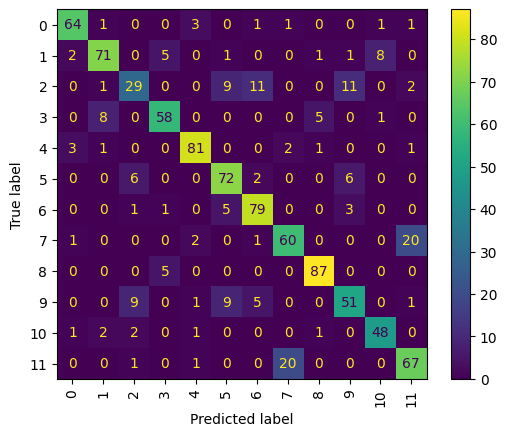

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
  y_spec_test, species_preds,
    xticks_rotation=90
)
plt.show()

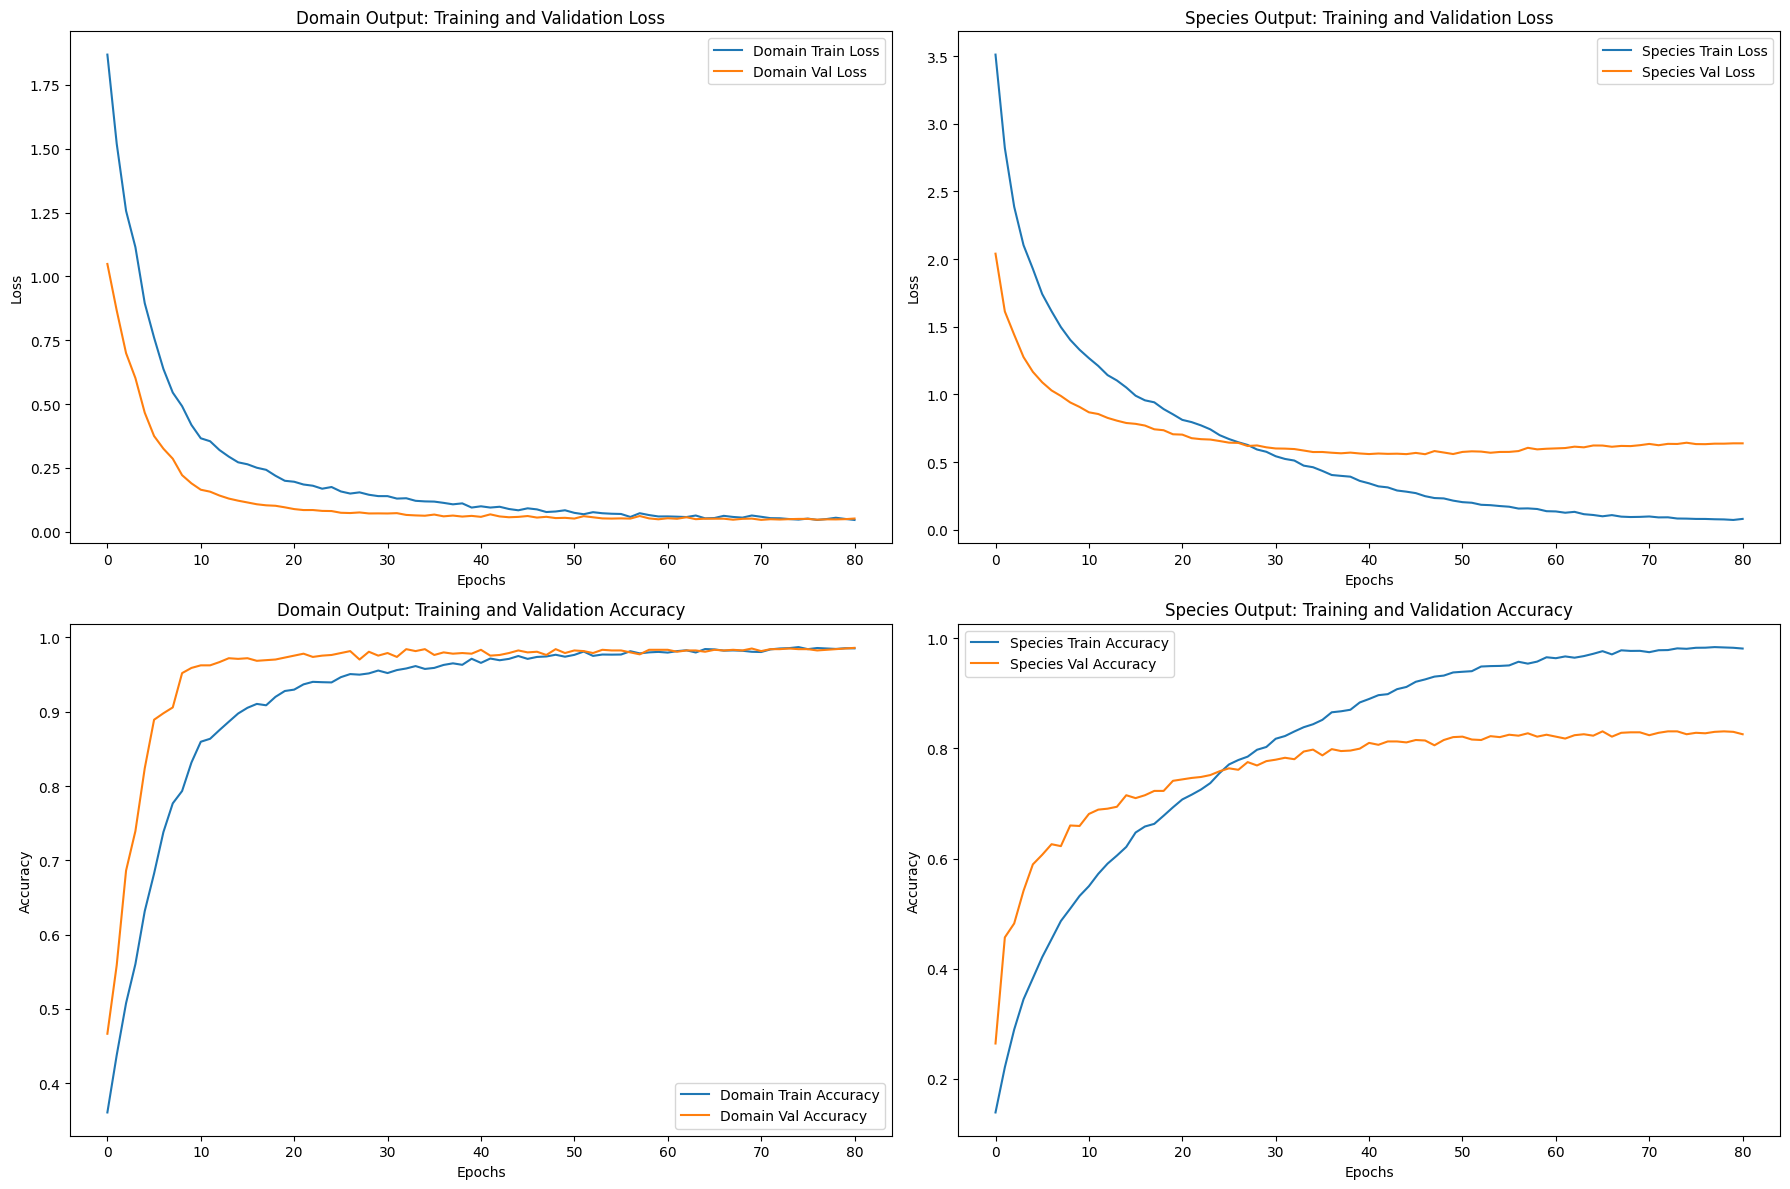

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['domain_output_loss'], label='Domain Train Loss')
plt.plot(history.history['val_domain_output_loss'], label='Domain Val Loss')
plt.title('Domain Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['species_output_loss'], label='Species Train Loss')
plt.plot(history.history['val_species_output_loss'], label='Species Val Loss')
plt.title('Species Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['domain_output_accuracy'], label='Domain Train Accuracy')
plt.plot(history.history['val_domain_output_accuracy'], label='Domain Val Accuracy')
plt.title('Domain Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['species_output_accuracy'], label='Species Train Accuracy')
plt.plot(history.history['val_species_output_accuracy'], label='Species Val Accuracy')
plt.title('Species Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def build_gated_hybrid_multitask(seq_len, kmer_dim, num_domains, num_species):

    dna_in = layers.Input(shape=(seq_len, 4), name="dna_input")


    x = layers.Conv1D(64, 15, activation='relu', padding='same')(dna_in)
    x = layers.BatchNormalization()(x)


    res = layers.Conv1D(64, 15, activation='relu', padding='same', dilation_rate=2)(x)
    res = layers.BatchNormalization()(res)
    res = layers.Conv1D(64, 15, activation=None, padding='same')(res)
    x = layers.Add()([x, res])
    x = layers.Activation('relu')(x)

    cnn_out = layers.GlobalAveragePooling1D()(x)
    cnn_proj = layers.Dense(256, activation='relu')(cnn_out)


    kmer_in = layers.Input(shape=(kmer_dim,), name="kmer_input")
    tab = layers.Dense(256, activation='relu')(kmer_in)
    tab = layers.Dropout(0.3)(tab)
    kmer_proj = layers.Dense(256, activation='relu')(tab)


    gate = layers.Dense(256, activation='sigmoid', name="gate_mechanism")(layers.Concatenate()([cnn_proj, kmer_proj]))


    gated_cnn = layers.Multiply()([cnn_proj, gate])
    merged = layers.Add()([gated_cnn, kmer_proj])


    z = layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.01))(merged)
    z = layers.BatchNormalization()(z)
    z = layers.Dropout(0.5)(z)


    z_spec = layers.Dense(256, activation='relu')(z)
    spec_out = layers.Dense(num_species, activation='softmax', name='species_output')(z_spec)


    z_dom = layers.Dense(64, activation='relu')(z)
    dom_out = layers.Dense(num_domains, activation='softmax', name='domain_output')(z_dom)

    return models.Model(inputs=[dna_in, kmer_in], outputs=[dom_out, spec_out])
model = build_gated_hybrid_multitask(500, 1024, 3, 12)

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss={
        'domain_output': 'sparse_categorical_crossentropy',
        'species_output': 'sparse_categorical_crossentropy'
    },
    loss_weights={'domain_output': 0.1, 'species_output': 1.0},
    metrics={'domain_output': 'accuracy', 'species_output': 'accuracy'}
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_species_output_accuracy',
        patience=15,
        restore_best_weights=True,
        mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_species_output_accuracy',
        factor=0.5,
        patience=5,
        mode='max',
        verbose=1
    )
]

history = model.fit(
    x=[X_train_final_dna, X_train_final_kmer],
    y={'domain_output': y_dom_train_final, 'species_output': y_spec_train_final},
    validation_data=(
        [X_val_dna, X_val_kmer],
        {'domain_output': y_dom_val, 'species_output': y_spec_val}
    ),
    epochs=150,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

preds = model.predict([X_test, X_km_test])

output_order = model.output_names
dom_idx = output_order.index('domain_output')
spec_idx = output_order.index('species_output')

species_preds = np.argmax(preds[spec_idx], axis=1)
dom_preds = np.argmax(preds[dom_idx], axis=1)

print("\n--- Final Species Classification Report (Unseen Test Data) ---")
print(classification_report(y_spec_test, species_preds))

print("\n--- Final Domain Classification Report (Unseen Test Data) ---")
print(classification_report(y_dom_test, dom_preds))

Epoch 1/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 98s 447ms/step - domain_output_accuracy: 0.4753 - domain_output_loss: 1.2033 - loss: 5.9440 - species_output_accuracy: 0.2086 - species_output_loss: 2.5235 - val_domain_output_accuracy: 0.7158 - val_domain_output_loss: 0.6973 - val_loss: 4.9769 - val_species_output_accuracy: 0.4176 - val_species_output_loss: 1.7169 - learning_rate: 1.0000e-04
Epoch 2/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 83s 407ms/step - domain_output_accuracy: 0.6825 - domain_output_loss: 0.7374 - loss: 4.8970 - species_output_accuracy: 0.3876 - species_output_loss: 1.7371 - val_domain_output_accuracy: 0.8718 - val_domain_output_loss: 0.3860 - val_loss: 4.3554 - val_species_output_accuracy: 0.4978 - val_species_output_loss: 1.3266 - learning_rate: 1.0000e-04
Epoch 3/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 83s 409ms/step - domain_output_accuracy: 0.8081 - domain_output_loss: 0.4741 - loss: 4.3839 - species_output_accuracy: 0.4722 - species_output_loss: 1.4463 - val_domain_output_accuracy: 0

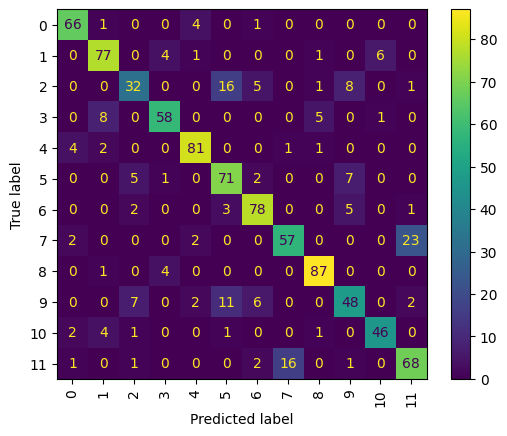

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
  y_spec_test, species_preds,
    xticks_rotation=90
)
plt.show()

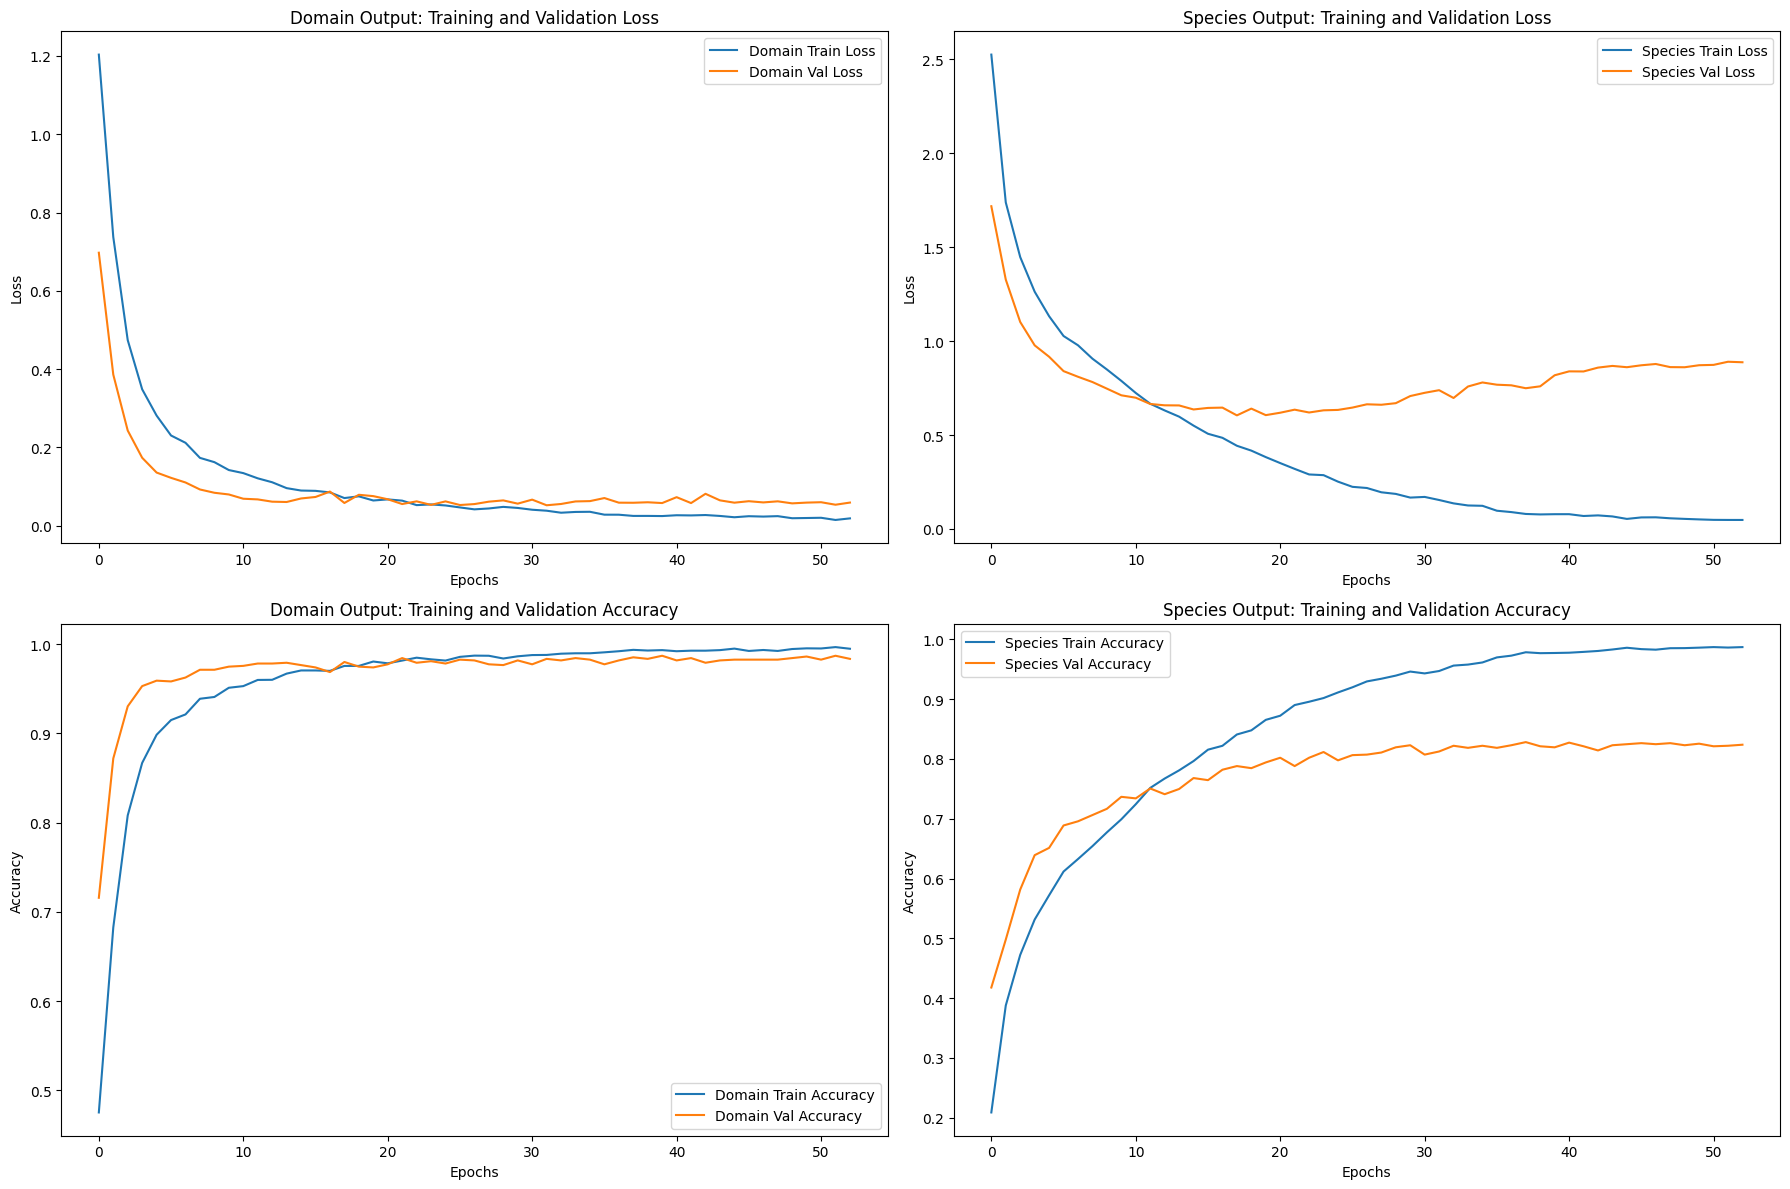

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['domain_output_loss'], label='Domain Train Loss')
plt.plot(history.history['val_domain_output_loss'], label='Domain Val Loss')
plt.title('Domain Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['species_output_loss'], label='Species Train Loss')
plt.plot(history.history['val_species_output_loss'], label='Species Val Loss')
plt.title('Species Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['domain_output_accuracy'], label='Domain Train Accuracy')
plt.plot(history.history['val_domain_output_accuracy'], label='Domain Val Accuracy')
plt.title('Domain Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['species_output_accuracy'], label='Species Train Accuracy')
plt.plot(history.history['val_species_output_accuracy'], label='Species Val Accuracy')
plt.title('Species Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def build_multiscale_attention_model(seq_len, kmer_dim, num_domains, num_species):
    # --- Branch 1: Multi-Scale CNN (The "Deep Vision" Branch) ---
    dna_in = layers.Input(shape=(seq_len, 4), name="dna_input")

    # 3 Parallel Windows to catch different motif lengths
    path1 = layers.Conv1D(48, 7, activation='relu', padding='same')(dna_in)
    path2 = layers.Conv1D(48, 15, activation='relu', padding='same')(dna_in)
    path3 = layers.Conv1D(48, 31, activation='relu', padding='same', dilation_rate=2)(dna_in)

    multi_scale = layers.Concatenate()([path1, path2, path3])
    multi_scale = layers.BatchNormalization()(multi_scale)

    # Squeeze-and-Excitation (Attention) Block
    # This helps the model focus on Rat-specific motifs vs generic Mammal ones
    se = layers.GlobalAveragePooling1D()(multi_scale)
    se = layers.Dense(multi_scale.shape[-1] // 4, activation='relu')(se)
    se = layers.Dense(multi_scale.shape[-1], activation='sigmoid')(se)
    se = layers.Reshape((1, multi_scale.shape[-1]))(se)
    x = layers.Multiply()([multi_scale, se])

    cnn_out = layers.GlobalMaxPooling1D()(x) # Catch the STRONGEST signal

    # --- Branch 2: Tabular (The "Statistical" Branch) ---
    kmer_in = layers.Input(shape=(kmer_dim,), name="kmer_input")
    # Wider first layer to handle the 1024 k-mer complexity
    tab = layers.Dense(512, activation='relu')(kmer_in)
    tab = layers.BatchNormalization()(tab)
    tab = layers.Dropout(0.4)(tab)
    tab_out = layers.Dense(256, activation='relu')(tab)

    # --- Feature Fusion ---
    merged = layers.Concatenate()([cnn_out, tab_out])

    # Final Decision Layers
    z = layers.Dense(512, activation='relu')(merged)
    z = layers.Dropout(0.5)(z)

    # Outputs
    dom_out = layers.Dense(num_domains, activation='softmax', name='domain_output')(z)
    spec_out = layers.Dense(num_species, activation='softmax', name='species_output')(z)

    return models.Model(inputs=[dna_in, kmer_in], outputs=[dom_out, spec_out])

# Compile with a very specific focus on Species
model = build_multiscale_attention_model(500, 1024, 3, 12)

In [ ]:
optimizer_adamw = tf.keras.optimizers.AdamW(
    learning_rate=0.0001,
    weight_decay=1e-4,  # Replaces high L2 penalty behavior at the optimizer step
    clipnorm=1.0        # Force clamps gradient explosions from the exponential activation
)

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

model.compile(
    optimizer=optimizer_adamw,
    loss={
        'domain_output': 'sparse_categorical_crossentropy',
        'species_output': 'sparse_categorical_crossentropy'
    },
    loss_weights={'domain_output': 0.1, 'species_output': 1.0},
    metrics={'domain_output': 'accuracy', 'species_output': 'accuracy'}
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_species_output_accuracy',
        patience=15,
        restore_best_weights=True,
        mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_species_output_accuracy',
        factor=0.5,
        patience=5,
        mode='max',
        verbose=1
    )
]

history = model.fit(
    x=[X_train_final_dna, X_train_final_kmer],
    y={'domain_output': y_dom_train_final, 'species_output': y_spec_train_final},
    validation_data=(
        [X_val_dna, X_val_kmer],
        {'domain_output': y_dom_val, 'species_output': y_spec_val}
    ),
    epochs=150,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

preds = model.predict([X_test, X_km_test])

output_order = model.output_names
dom_idx = output_order.index('domain_output')
spec_idx = output_order.index('species_output')

species_preds = np.argmax(preds[spec_idx], axis=1)
dom_preds = np.argmax(preds[dom_idx], axis=1)

print("\n--- Final Species Classification Report (Unseen Test Data) ---")
print(classification_report(y_spec_test, species_preds))

print("\n--- Final Domain Classification Report (Unseen Test Data) ---")
print(classification_report(y_dom_test, dom_preds))

Epoch 1/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 34s 119ms/step - domain_output_accuracy: 0.4570 - domain_output_loss: 1.1706 - loss: 2.4070 - species_output_accuracy: 0.2500 - species_output_loss: 2.2947 - val_domain_output_accuracy: 0.7951 - val_domain_output_loss: 0.6564 - val_loss: 1.6410 - val_species_output_accuracy: 0.4682 - val_species_output_loss: 1.5758 - learning_rate: 1.0000e-04
Epoch 2/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 24s 115ms/step - domain_output_accuracy: 0.7310 - domain_output_loss: 0.6257 - loss: 1.5132 - species_output_accuracy: 0.4822 - species_output_loss: 1.4609 - val_domain_output_accuracy: 0.9111 - val_domain_output_loss: 0.3392 - val_loss: 1.1445 - val_species_output_accuracy: 0.6103 - val_species_output_loss: 1.1112 - learning_rate: 1.0000e-04
Epoch 3/150
204/204 ━━━━━━━━━━━━━━━━━━━━ 42s 121ms/step - domain_output_accuracy: 0.8564 - domain_output_loss: 0.3946 - loss: 1.1737 - species_output_accuracy: 0.5795 - species_output_loss: 1.1509 - val_domain_output_accuracy: 0

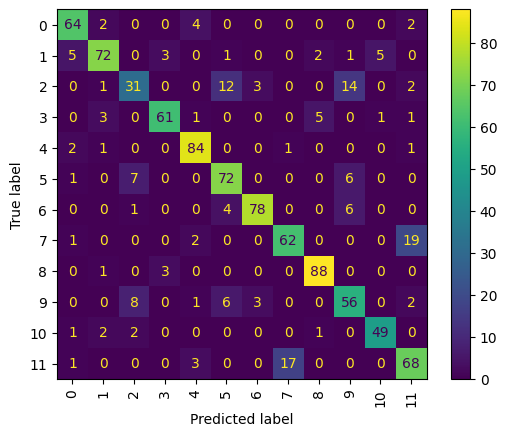

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
  y_spec_test, species_preds,
    xticks_rotation=90
)
plt.show()

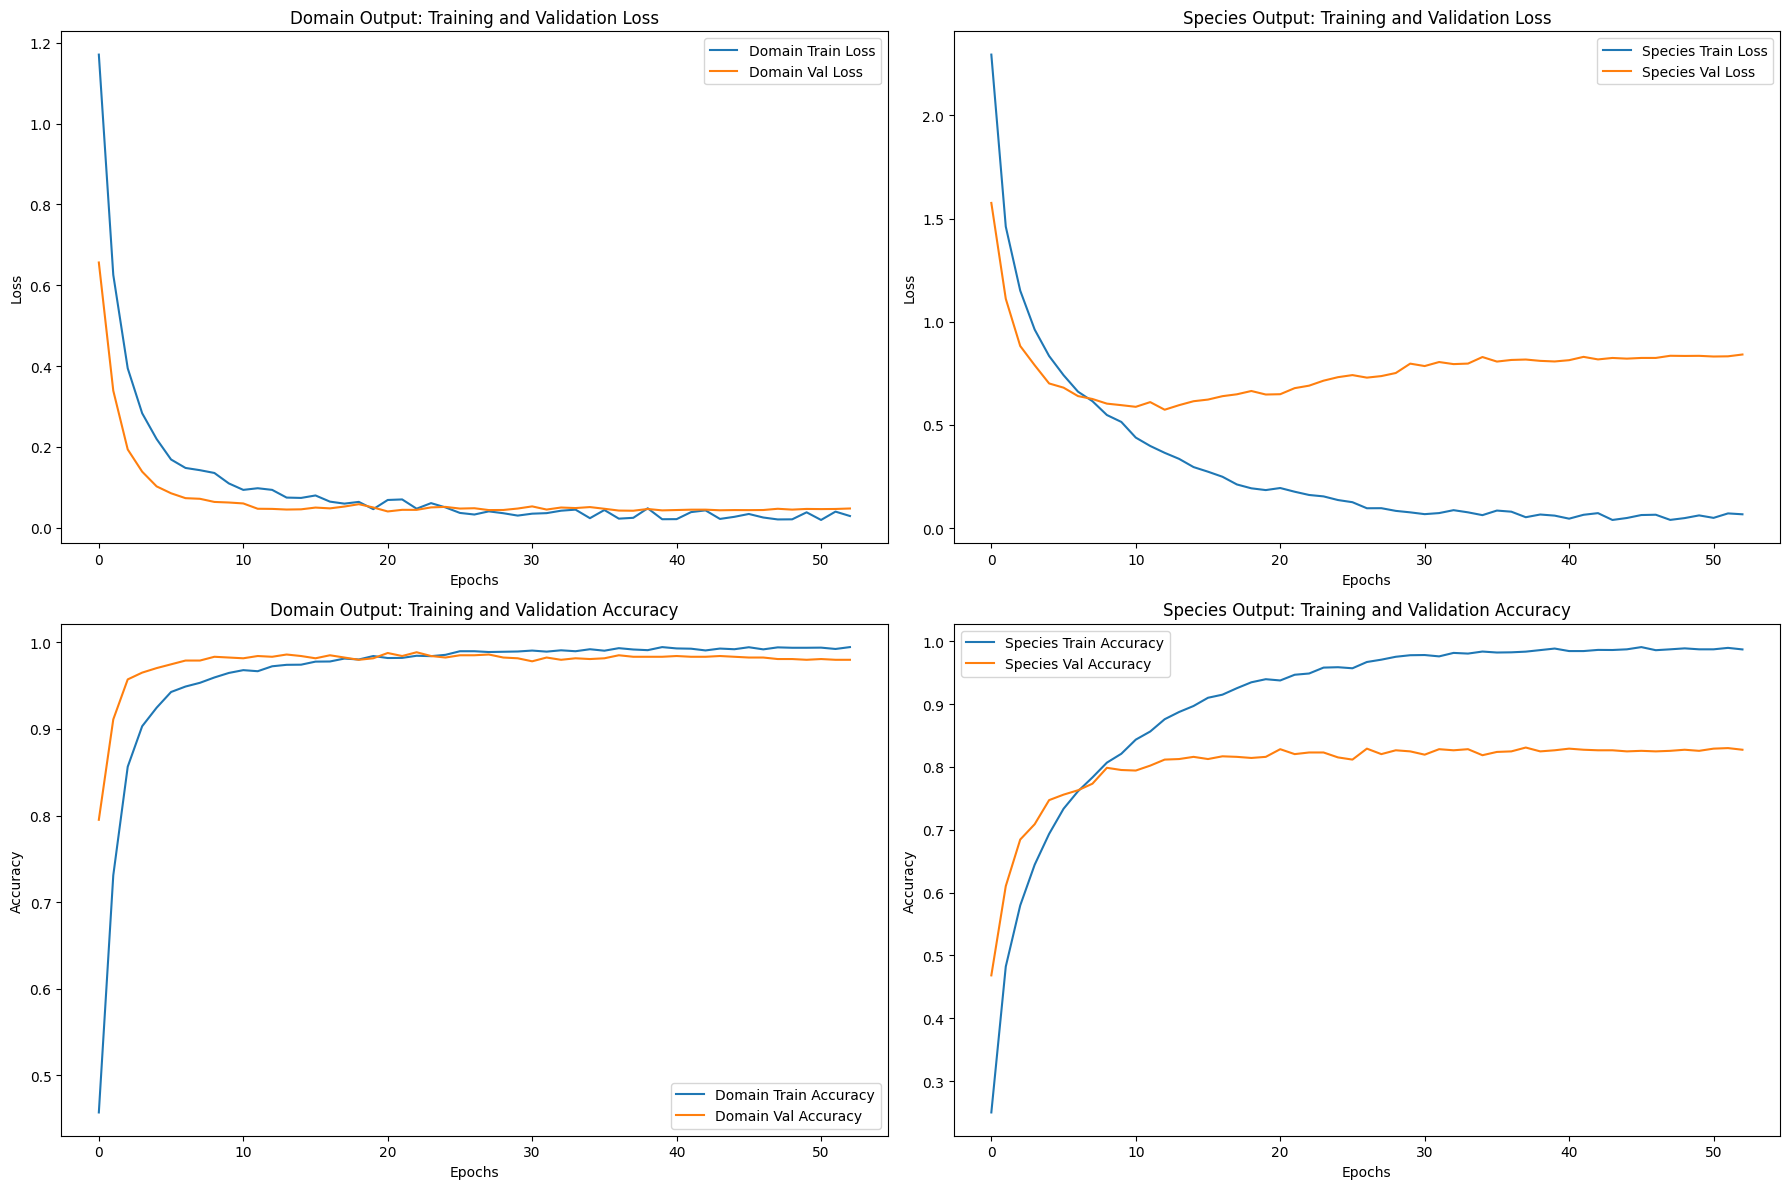

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['domain_output_loss'], label='Domain Train Loss')
plt.plot(history.history['val_domain_output_loss'], label='Domain Val Loss')
plt.title('Domain Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['species_output_loss'], label='Species Train Loss')
plt.plot(history.history['val_species_output_loss'], label='Species Val Loss')
plt.title('Species Output: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['domain_output_accuracy'], label='Domain Train Accuracy')
plt.plot(history.history['val_domain_output_accuracy'], label='Domain Val Accuracy')
plt.title('Domain Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['species_output_accuracy'], label='Species Train Accuracy')
plt.plot(history.history['val_species_output_accuracy'], label='Species Val Accuracy')
plt.title('Species Output: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

This cell imports essential libraries for data manipulation, machine learning, and deep learning. `pandas` and `numpy` are used for data structures and numerical operations. `sklearn` provides utilities like `train_test_split` for data partitioning, `LabelEncoder` for categorical feature conversion, and `classification_report` for model evaluation. `tensorflow` and `keras` are the core libraries for building and training neural networks. `matplotlib` is used for data visualization.